# YZ50 — Week 11: Optimizing GPT-2 Training

- **From memorizing a batch to reading the text.** Week 10 ended with my GPT-2 memorizing one fixed batch. Training on a corpus needs a **data loader** that walks through all of the tokens.

- **Weight tying and initialization.** The input embedding and the output projection share one matrix, and residual projections start smaller so that the residual stream does not grow with depth.

- **Training throughput.** Most of the speed of a training step comes from how the arithmetic is done, not from the model: **TF32**, **BF16 autocast**, **optimized attention kernels**, **`torch.compile`**, and a **hardware-friendly vocabulary size**. These need measurements, because their gain depends on the GPU.

- **GPT-3 training settings.** **AdamW** with \(\beta_1=0.9,\ \beta_2=0.95,\ \epsilon=10^{-8}\), **gradient clipping**, a **warmup + cosine learning rate**, **weight decay only on 2D parameters**, and **gradient accumulation** to simulate a batch that does not fit in memory.

In this week, I follow the part of Karpathy's GPT-2 lecture from 1:02:00 to 2:46:52. I reuse my Week 10 GPT-2 with random weights, train it over all of Tiny Shakespeare with a sequential data loader, benchmark each speed-up cumulatively on my RTX 3060 Laptop GPU, and then combine everything in a short training run. Full GPT-2 pretraining is not part of this week.

In [1]:
from pathlib import Path
import gc
import math
import statistics
import time
import warnings
from dataclasses import dataclass
import importlib.util
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.nn import functional as F
from torch.nn.attention import sdpa_kernel, SDPBackend
import tiktoken
from IPython.display import display, Markdown

seed = 1337
torch.manual_seed(seed)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
# works from the repository root and from week-11/
repo_dir = Path.cwd() if (Path.cwd() / 'week-10').exists() else Path.cwd().parent
input_path = repo_dir / 'week-10' / 'input.txt'
output_dir = repo_dir / 'week-11'
assert input_path.exists()
print('PyTorch:', torch.__version__, '| tiktoken:', tiktoken.__version__)
print('device:', device)
if device == 'cuda':
    props = torch.cuda.get_device_properties(0)
    print(f'GPU: {props.name} | memory: {props.total_memory / 2**30:.1f} GiB | compute capability: {props.major}.{props.minor}')

PyTorch: 2.14.0+cu126 | tiktoken: 0.14.0
device: cuda
GPU: NVIDIA GeForce RTX 3060 Laptop GPU | memory: 6.0 GiB | compute capability: 8.6


## Numerical Precision Switch

As in Week 10, I start in full float32. TF32 is one of the settings being measured, so it must be off until the benchmark enables it. `set_tf32` is the only place that changes it.

In [2]:
def set_tf32(enabled):
    torch.backends.cuda.matmul.allow_tf32 = enabled
    torch.backends.cudnn.allow_tf32 = enabled
    torch.set_float32_matmul_precision('high' if enabled else 'highest')

def release_memory():
    gc.collect()
    if device == 'cuda':
        torch.cuda.empty_cache()

set_tf32(False)
print('TF32 matmul:', torch.backends.cuda.matmul.allow_tf32, '| float32 matmul precision:', torch.get_float32_matmul_precision())

TF32 matmul: False | float32 matmul precision: highest


# 1. Data loader, weight tying ve başlangıç değerleri. Metni batch'lere bölen küçük bir data loader yaz ve metnin tamamında eğit. Weight tying'i ekle, kaç parametre kazandırdığını hesapla. Başlangıç değerlerini videodaki gibi ayarla: std 0.02, residual katmanlarda 1/√(2·n_layer) ile ölçekleme. Neden ölçeklediğimizi kendi cümlelerinle yaz. Geçen hafta ek görevde yaptıysan kısaca göstermen yeterli. (1:02:00 - 1:22:18)

## 1. Data Loader, Weight Tying, and Initialization

### The GPT-2 Model from Week 10

The modules are my Week 10 definitions: fused `c_attn`, GELU with the tanh approximation, pre-normalized blocks, and `lm_head` tied to `wte`. There is one addition, needed for Task 2: `GPTConfig.sdpa` selects between my explicit attention formula and `F.scaled_dot_product_attention`. The triangular mask is only created for the explicit version.

No pretrained weights are used this week. Every model here starts from random weights.

In [3]:
@dataclass
class GPTConfig:
    block_size: int = 1024 # max sequence length
    vocab_size: int = 50257 # 50,000 BPE merges + 256 bytes tokens + 1 <|endoftext|> token
    n_layer: int = 12 # number of layers
    n_head: int = 12 # number of heads
    n_embd: int = 768 # embedding dimension
    sdpa: bool = False # False: explicit attention as in Week 10, True: F.scaled_dot_product_attention


class CausalSelfAttention(nn.Module):

    def __init__(self, config):
        super().__init__()
        assert config.n_embd % config.n_head == 0
        # key, query, value projections for all heads, but in a batch
        self.c_attn = nn.Linear(config.n_embd, 3 * config.n_embd)
        # output projection
        self.c_proj = nn.Linear(config.n_embd, config.n_embd)
        self.n_head = config.n_head
        self.n_embd = config.n_embd
        self.sdpa = config.sdpa
        if not self.sdpa:
            # causal mask, not a learned weight and not saved in the state dict
            tril = torch.tril(torch.ones(config.block_size, config.block_size))
            self.register_buffer('tril', tril.view(1, 1, config.block_size, config.block_size), persistent=False)

    def forward(self, x):
        B, T, C = x.size() # batch size, sequence length, embedding dimensionality (n_embd)
        qkv = self.c_attn(x) # (B,T,3C)
        q, k, v = qkv.split(self.n_embd, dim=2) # each (B,T,C)
        # nh is "number of heads", hs is "head size", and C (number of channels) = nh * hs
        k = k.view(B, T, self.n_head, C // self.n_head).transpose(1, 2) # (B,nh,T,hs)
        q = q.view(B, T, self.n_head, C // self.n_head).transpose(1, 2) # (B,nh,T,hs)
        v = v.view(B, T, self.n_head, C // self.n_head).transpose(1, 2) # (B,nh,T,hs)
        if self.sdpa:
            # one optimized kernel; PyTorch chooses the backend
            y = F.scaled_dot_product_attention(q, k, v, is_causal=True)
        else:
            # attention (materializes the large (T,T) matrix for all the queries and keys)
            att = (q @ k.transpose(-2, -1)) * (1.0 / math.sqrt(k.size(-1))) # (B,nh,T,T)
            att = att.masked_fill(self.tril[:, :, :T, :T] == 0, float('-inf'))
            att = F.softmax(att, dim=-1)
            y = att @ v # (B,nh,T,T) @ (B,nh,T,hs) -> (B,nh,T,hs)
        y = y.transpose(1, 2).contiguous().view(B, T, C) # re-assemble all head outputs side by side
        # output projection
        y = self.c_proj(y)
        return y


class MLP(nn.Module):

    def __init__(self, config):
        super().__init__()
        self.c_fc = nn.Linear(config.n_embd, 4 * config.n_embd)
        self.gelu = nn.GELU(approximate='tanh')
        self.c_proj = nn.Linear(4 * config.n_embd, config.n_embd)

    def forward(self, x):
        x = self.c_fc(x) # (B,T,4C)
        x = self.gelu(x)
        x = self.c_proj(x) # (B,T,C)
        return x


class Block(nn.Module):

    def __init__(self, config):
        super().__init__()
        self.ln_1 = nn.LayerNorm(config.n_embd)
        self.attn = CausalSelfAttention(config)
        self.ln_2 = nn.LayerNorm(config.n_embd)
        self.mlp = MLP(config)

    def forward(self, x):
        x = x + self.attn(self.ln_1(x)) # communication
        x = x + self.mlp(self.ln_2(x)) # computation
        return x


class GPT(nn.Module):

    def __init__(self, config):
        super().__init__()
        self.config = config

        self.transformer = nn.ModuleDict(dict(
            wte = nn.Embedding(config.vocab_size, config.n_embd),
            wpe = nn.Embedding(config.block_size, config.n_embd),
            h = nn.ModuleList([Block(config) for _ in range(config.n_layer)]),
            ln_f = nn.LayerNorm(config.n_embd),
        ))
        self.lm_head = nn.Linear(config.n_embd, config.vocab_size, bias=False)

        # weight sharing scheme: one (vocab_size, n_embd) matrix for the input and the output
        self.transformer.wte.weight = self.lm_head.weight

    def forward(self, idx, targets=None):
        # idx is of shape (B, T)
        B, T = idx.size()
        assert T <= self.config.block_size, f"Cannot forward sequence of length {T}, block size is only {self.config.block_size}"
        # forward the token and position embeddings
        pos = torch.arange(0, T, dtype=torch.long, device=idx.device) # shape (T)
        pos_emb = self.transformer.wpe(pos) # position embeddings of shape (T, n_embd)
        tok_emb = self.transformer.wte(idx) # token embeddings of shape (B, T, n_embd)
        x = tok_emb + pos_emb
        # forward the blocks of the transformer
        for block in self.transformer.h:
            x = block(x)
        # forward the final layernorm and the classifier
        x = self.transformer.ln_f(x)
        logits = self.lm_head(x) # (B, T, vocab_size)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1))
        return logits, loss

print(GPTConfig())

GPTConfig(block_size=1024, vocab_size=50257, n_layer=12, n_head=12, n_embd=768, sdpa=False)


### The Data Loader

In Week 10, the batch never changed. `DataLoaderLite` tokenizes the corpus once and keeps a position in it. To produce a batch it reads \(B\cdot T+1\) tokens: the extra token exists because the target of the last input is the token after it.

\[
\texttt{buf}=[t_0,\dots,t_{BT}],\qquad x=\texttt{buf}[:-1]\ \text{viewed as }(B,T),\qquad y=\texttt{buf}[1:]\ \text{viewed as }(B,T)
\]

The position then advances by \(B\cdot T\), not \(B\cdot T+1\), so no token is skipped as an input. When fewer than \(B\cdot T+1\) tokens remain, the loader wraps to the beginning and counts one epoch. The final partial batch is dropped.

The tokens stay on the CPU; each batch moves to the GPU in the training loop. The corpus is Tiny Shakespeare from `week-10/input.txt`, encoded with the GPT-2 tokenizer.

In [4]:
class DataLoaderLite:

    def __init__(self, tokens, B, T):
        self.tokens = tokens # 1D tensor holding the whole corpus
        self.B = B
        self.T = T
        assert len(tokens) >= B * T + 1, 'corpus is shorter than one batch'
        self.current_position = 0
        self.epoch = 0

    def next_batch(self):
        B, T = self.B, self.T
        buf = self.tokens[self.current_position : self.current_position + B * T + 1]
        x = buf[:-1].view(B, T) # inputs
        y = buf[1:].view(B, T) # targets
        self.current_position += B * T
        # if the next batch would be out of bounds, wrap to the beginning
        if self.current_position + B * T + 1 > len(self.tokens):
            self.current_position = 0
            self.epoch += 1
        return x, y

enc = tiktoken.get_encoding('gpt2')
text = input_path.read_text(encoding='utf-8')
tokens = torch.tensor(enc.encode(text), dtype=torch.long)
print(f'{input_path.name}: {len(text):,} characters -> {len(tokens):,} GPT-2 tokens ({len(text) / len(tokens):.2f} characters per token)')
print('first tokens:', tokens[:8].tolist(), '->', repr(enc.decode(tokens[:8].tolist())))
print('token ID range:', tokens.min().item(), 'to', tokens.max().item())
assert tokens.max() < 50257

input.txt: 1,115,394 characters -> 338,025 GPT-2 tokens (3.30 characters per token)
first tokens: [5962, 22307, 25, 198, 8421, 356, 5120, 597] -> 'First Citizen:\nBefore we proceed any'
token ID range: 0 to 50255


#### Checks on the Loader

The checks below test the properties that training relies on: targets are the inputs shifted by exactly one token (also across row boundaries), consecutive batches differ and continue each other, one epoch visits the whole corpus in order, and wrapping returns to the first batch.

In [5]:
B, T = 4, 8
loader = DataLoaderLite(tokens, B, T)
x1, y1 = loader.next_batch()
x2, y2 = loader.next_batch()
print('x', tuple(x1.shape), '| y', tuple(y1.shape))
print('x[0]:', x1[0].tolist())
print('y[0]:', y1[0].tolist())
print('text of x[0]:', repr(enc.decode(x1[0].tolist())))
print('text of y[0]:', repr(enc.decode(y1[0].tolist())))

# targets are the inputs shifted by one position, also across row boundaries
assert x1.shape == y1.shape == (B, T)
assert torch.equal(y1[:, :-1], x1[:, 1:])
assert torch.equal(y1[:-1, -1], x1[1:, 0])
assert torch.equal(x1.view(-1)[1:], y1.view(-1)[:-1])
# successive batches are different and continue each other
assert not torch.equal(x1, x2)
assert y1[-1, -1] == x2[0, 0]

# one full epoch over a small corpus: B*T*n tokens + 1 fit exactly n batches
small = torch.arange(4 * 8 * 5 + 1 + 10) # 10 tail tokens cannot fill a batch
small_loader = DataLoaderLite(small, 4, 8)
seen = []
for _ in range(5):
    assert small_loader.epoch == 0
    seen.append(small_loader.next_batch()[0].view(-1))
assert torch.equal(torch.cat(seen), small[:4 * 8 * 5]) # all in order, nothing skipped or repeated
assert small_loader.epoch == 1 and small_loader.current_position == 0
assert torch.equal(small_loader.next_batch()[0].view(-1), small[:4 * 8]) # wrapped safely

# every batch of the real corpus keeps its full shape across a wrap
wrap_loader = DataLoaderLite(tokens, 8, 128)
steps_per_epoch = (len(tokens) - 1) // (8 * 128)
for _ in range(steps_per_epoch + 2):
    xb, yb = wrap_loader.next_batch()
    assert xb.shape == yb.shape == (8, 128)
assert wrap_loader.epoch == 1
try:
    DataLoaderLite(tokens[:10], 4, 8)
    too_small_checked = False
except AssertionError as e:
    too_small_checked = True
    print('AssertionError:', e)
assert too_small_checked
print(f'(8, 128) batches per epoch: {steps_per_epoch} | tokens dropped at the wrap: {len(tokens) - 1 - steps_per_epoch * 8 * 128}')
print('Target-shift, successive-batch, full-epoch, and wrap checks passed.')

x (4, 8) | y (4, 8)
x[0]: [5962, 22307, 25, 198, 8421, 356, 5120, 597]
y[0]: [22307, 25, 198, 8421, 356, 5120, 597, 2252]
text of x[0]: 'First Citizen:\nBefore we proceed any'
text of y[0]: ' Citizen:\nBefore we proceed any further'
AssertionError: corpus is shorter than one batch
(8, 128) batches per epoch: 330 | tokens dropped at the wrap: 104
Target-shift, successive-batch, full-epoch, and wrap checks passed.


### Weight Tying

`wte.weight` and `lm_head.weight` are both `(vocab_size, n_embd)`: one vector per token. The line `self.transformer.wte.weight = self.lm_head.weight` makes them **one** `nn.Parameter`. Without tying, GPT-2 would need another

\[
50257\times768 = 38{,}597{,}376
\]

independent numbers.

Two counts must be kept apart. `model.parameters()` yields a shared parameter **once**, so it gives the number of unique trainable numbers. `state_dict()` has **one entry per name**, so the same matrix is listed twice and the sum over its entries counts it twice. I measured this difference in Week 10 as well; here it is repeated on the model I am going to train.

In [6]:
def init_gpt2_weights(model):
    n_layer = model.config.n_layer
    for name, module in model.named_modules():
        if isinstance(module, nn.Linear):
            std = 0.02
            if name.endswith('c_proj'): # projections that add into the residual stream
                std *= (2 * n_layer) ** -0.5
            torch.nn.init.normal_(module.weight, mean=0.0, std=std)
            if module.bias is not None:
                torch.nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)
        elif isinstance(module, nn.LayerNorm):
            torch.nn.init.ones_(module.weight)
            torch.nn.init.zeros_(module.bias)

def build_model(config):
    torch.manual_seed(seed) # the same seed always gives the same initial weights
    model = GPT(config)
    init_gpt2_weights(model)
    return model.to(device)

model = build_model(GPTConfig())
n_unique = sum(p.numel() for p in model.parameters())
n_state_dict = sum(v.numel() for v in model.state_dict().values())
n_saved = model.lm_head.weight.numel()
print(f'unique parameters:            {n_unique:>12,}')
print(f'sum over state-dict entries:  {n_state_dict:>12,} (the shared matrix is listed under two names)')
print(f'saved by weight tying:        {n_saved:>12,} = {50257} x {768}')
print(f'share of an untied model:     {n_saved / (n_unique + n_saved):>12.1%}')

assert model.lm_head.weight is model.transformer.wte.weight
assert model.lm_head.weight.data_ptr() == model.transformer.wte.weight.data_ptr()
assert n_saved == 50257 * 768 == 38_597_376
assert n_unique == 124_439_808
assert n_state_dict == n_unique + n_saved
print('Weight-tying and parameter-count checks passed.')

unique parameters:             124,439,808
sum over state-dict entries:   163,037,184 (the shared matrix is listed under two names)
saved by weight tying:          38,597,376 = 50257 x 768
share of an untied model:            23.7%
Weight-tying and parameter-count checks passed.


### Initialization

`init_gpt2_weights` above follows the lecture:

- **Linear and embedding weights:** \(\mathcal{N}(0,0.02^2)\).
- **Linear biases:** zero. **LayerNorm:** weight one, bias zero.
- **Residual projections** (`attn.c_proj`, `mlp.c_proj`): standard deviation \(0.02/\sqrt{2\,n_{layer}}\).

**Why I scale the residual layers.** The residual stream is a running sum: every block adds something to `x` and passes it on. If the added parts are roughly independent with variance \(\sigma^2\), then after \(N\) additions the variance of the sum is \(N\sigma^2\), so the stream's standard deviation grows like \(\sqrt{N}\) and a deeper model starts with a louder signal. Each block adds twice (attention and MLP), so \(N=2\,n_{layer}\). Dividing the standard deviation of the layers that produce these additions by \(\sqrt{N}\) divides each addition's variance by \(N\), which cancels the growth. Each block then starts as a small correction to the stream instead of adding noise on top of it.

The next cell first shows the arithmetic on random vectors, as in the lecture, and then measures the residual stream of the real 12-block model with and without the scaling.

sum of 100 random vectors: std 9.923 | with each scaled by 1/sqrt(100): std 0.999


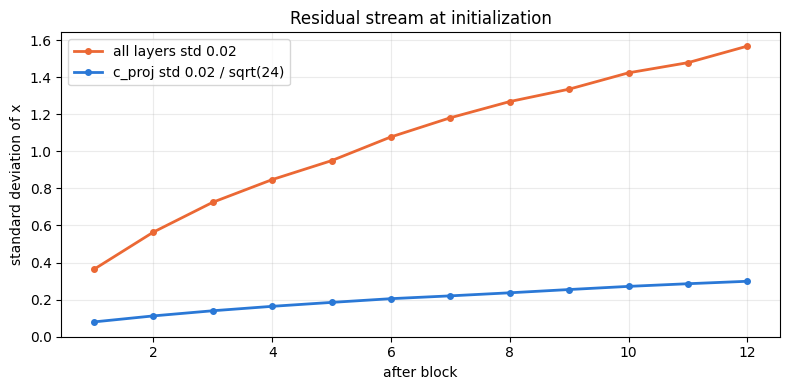

std after blocks 1 and 12, unscaled: 0.364 1.5674
std after blocks 1 and 12, scaled:   0.0799 0.2991


In [7]:
torch.manual_seed(seed)
n = 100
unscaled = torch.zeros(768)
scaled = torch.zeros(768)
for _ in range(n):
    unscaled += torch.randn(768)
    scaled += n ** -0.5 * torch.randn(768)
print(f'sum of {n} random vectors: std {unscaled.std():.3f} | with each scaled by 1/sqrt({n}): std {scaled.std():.3f}')

def residual_stream_stds(model, idx):
    # standard deviation of x after token + position embedding, and after every block
    stds = []
    hooks = [block.register_forward_hook(lambda m, i, o: stds.append(o.std().item())) for block in model.transformer.h]
    with torch.no_grad():
        model(idx)
    for hook in hooks:
        hook.remove()
    return stds

xb, _ = DataLoaderLite(tokens, 4, 128).next_batch()
xb = xb.to(device)
stds_scaled = residual_stream_stds(model, xb)

unscaled_model = build_model(GPTConfig())
torch.manual_seed(seed)
for name, module in unscaled_model.named_modules():
    if name.endswith('c_proj'):
        torch.nn.init.normal_(module.weight, mean=0.0, std=0.02) # no 1/sqrt(2 * n_layer)
stds_unscaled = residual_stream_stds(unscaled_model, xb)
del unscaled_model
release_memory()

blocks = range(1, len(stds_scaled) + 1)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(blocks, stds_unscaled, color='#eb6834', linewidth=2, marker='o', markersize=4, label='all layers std 0.02')
ax.plot(blocks, stds_scaled, color='#2a78d6', linewidth=2, marker='o', markersize=4, label='c_proj std 0.02 / sqrt(24)')
ax.set_title('Residual stream at initialization')
ax.set_xlabel('after block')
ax.set_ylabel('standard deviation of x')
ax.set_ylim(bottom=0)
ax.grid(alpha=0.25)
ax.legend()
plt.tight_layout()
plt.show()
print('std after blocks 1 and 12, unscaled:', round(stds_unscaled[0], 4), round(stds_unscaled[-1], 4))
print('std after blocks 1 and 12, scaled:  ', round(stds_scaled[0], 4), round(stds_scaled[-1], 4))
assert stds_scaled[-1] < stds_unscaled[-1]

In [8]:
block0 = model.transformer.h[0]
expected_residual_std = 0.02 / math.sqrt(2 * model.config.n_layer)
residual_w = torch.cat([p.view(-1) for n_, p in model.named_parameters() if n_.endswith('c_proj.weight')])
other_w = torch.cat([p.view(-1) for n_, p in model.named_parameters() if n_.endswith(('c_attn.weight', 'c_fc.weight'))])
print(f'wte (= lm_head) std:      {model.transformer.wte.weight.std().item():.5f}')
print(f'wpe std:                  {model.transformer.wpe.weight.std().item():.5f}')
print(f'c_attn and c_fc std:      {other_w.std().item():.5f}')
print(f'all residual c_proj std:  {residual_w.std().item():.5f} (0.02 / sqrt(24) = {expected_residual_std:.5f})')

assert abs(model.transformer.wte.weight.std().item() - 0.02) < 2e-4
assert abs(model.transformer.wpe.weight.std().item() - 0.02) < 2e-4
assert abs(other_w.std().item() - 0.02) < 2e-4
assert abs(residual_w.std().item() - expected_residual_std) < 5e-5
assert all(m.bias.abs().max() == 0 for m in model.modules() if isinstance(m, nn.Linear) and m.bias is not None)
layernorms = [m for m in model.modules() if isinstance(m, nn.LayerNorm)]
assert len(layernorms) == 2 * 12 + 1
assert all((m.weight == 1).all() and (m.bias == 0).all() for m in layernorms)
assert model.lm_head.weight is model.transformer.wte.weight # initialization did not break the tie
print('Initialization checks passed.')

wte (= lm_head) std:      0.02000
wpe std:                  0.01998
c_attn and c_fc std:      0.02000
all residual c_proj std:  0.00408 (0.02 / sqrt(24) = 0.00408)
Initialization checks passed.


### Training over the Whole Corpus

This is the first time the model sees more than one batch. With batch `(8, 128)`, one epoch of Tiny Shakespeare is the number of steps computed above, and I run exactly one epoch, so every batch is different and each token is an input once. The settings stay simple on purpose: AdamW with a constant \(3\times10^{-4}\), float32, no TF32, no warmup, no clipping. Task 3 adds the rest.

The batch changes every step, so the loss is noisier than the fixed-batch curve of Week 10 and it should not approach zero: the model cannot memorize text it only sees once. This is training loss; I do not measure a held-out loss here.

step    1 | loss 10.9610


step   30 | loss 6.3016


step   60 | loss 6.2693


step   90 | loss 6.4205


step  120 | loss 5.7661


step  150 | loss 5.8779


... (2 outputs left out)

step  240 | loss 5.8943


step  270 | loss 5.7489


step  300 | loss 5.7339


step  330 | loss 5.6142
330 steps, 337,920 tokens in 75.0 s (227 ms per step)
mean loss, first 20 steps: 7.8582 | last 20 steps: 5.4498


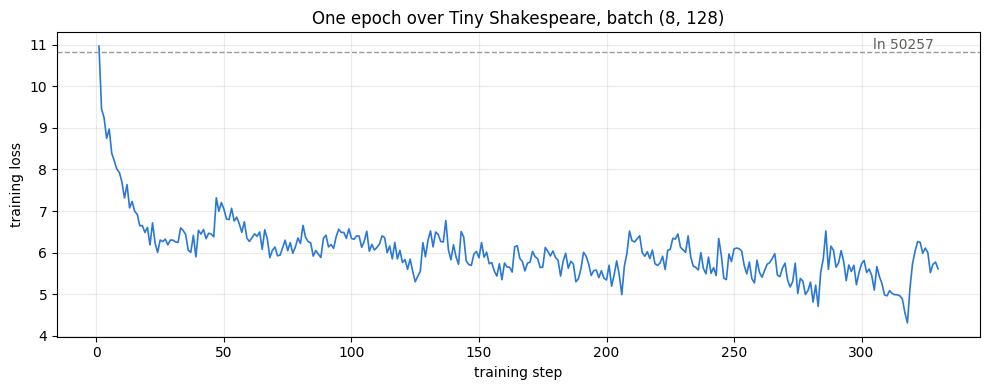

In [9]:
torch.manual_seed(seed)
loader = DataLoaderLite(tokens, 8, 128)
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4)
task1_losses = []
batches_seen = set()
t0 = time.perf_counter()
step = 0
while loader.epoch == 0: # exactly one pass over the corpus
    x, y = loader.next_batch()
    batches_seen.add(tuple(x[0, :16].tolist()))
    x, y = x.to(device), y.to(device)
    optimizer.zero_grad(set_to_none=True)
    logits, loss = model(x, y)
    loss.backward()
    optimizer.step()
    step += 1
    task1_losses.append(loss.item())
    assert math.isfinite(task1_losses[-1])
    if step == 1 or step % 30 == 0:
        print(f'step {step:4d} | loss {task1_losses[-1]:.4f}')
elapsed = time.perf_counter() - t0
print(f'{step} steps, {step * 8 * 128:,} tokens in {elapsed:.1f} s ({elapsed / step * 1000:.0f} ms per step)')
print(f'mean loss, first 20 steps: {sum(task1_losses[:20]) / 20:.4f} | last 20 steps: {sum(task1_losses[-20:]) / 20:.4f}')

assert step == steps_per_epoch
assert len(batches_seen) == step # no batch was repeated
assert sum(task1_losses[-20:]) < sum(task1_losses[:20])

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(range(1, step + 1), task1_losses, color='#2a78d6', linewidth=1.2)
ax.axhline(math.log(50257), color='#9a9a94', linewidth=1, linestyle='--')
ax.text(step, math.log(50257), 'ln 50257 ', ha='right', va='bottom', color='#5f5f5a')
ax.set_title('One epoch over Tiny Shakespeare, batch (8, 128)')
ax.set_xlabel('training step')
ax.set_ylabel('training loss')
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()
del model, optimizer, logits, loss, x, y, xb
release_memory()

### Reading the Task 1 Results

**Residual stream.** On random vectors, the sum of 100 additions reaches a standard deviation of 9.92, and scaling each by \(1/\sqrt{100}\) brings it back to 1.00. In the real model the picture is similar but not identical. Scaling does **not** make the curve flat: within one model, the stream still grows from block to block (from 0.080 to 0.299), because the additions are still accumulating. What scaling controls is the level the stream reaches at the end of the stack: 0.299 with scaling against 1.567 without, a factor of 5.2, close to \(\sqrt{24}\approx4.9\). This is what the rule promises: the total variance after all \(2n_{layer}\) additions no longer depends on the number of layers.

**Weight tying.** The two names are one object with one storage. Tying saves 38,597,376 parameters: 23.7% of an untied model, or 31% relative to the tied 124,439,808.

**Training.** One epoch of 330 steps reads 337,920 of the 338,025 tokens as inputs. Of the 105 left over, one is used only as the target of the last batch, and the other 104 cannot fill a batch. The loss starts at 10.96, close to the \(\ln 50257\approx10.82\) of a uniform guess. The mean over the first 20 steps is 7.86 and over the last 20 it is 5.45, while single batches vary (step 330 is 5.61).

Unlike the 0.0032 of Week 10, this value is far from zero, and that is the expected difference: Week 10 repeated the same 512 tokens 500 times, while here each token passes once as an input. A loss near 5.5 after one epoch means that the model has learned something about the text's token statistics, not that it can write well. I did not measure held-out loss or generate samples, so I can make no claim about generalization.

# 2. Eğitimi hızlandır. Bir eğitim adımının süresini ve saniyede işlenen token sayısını ölç. Sonra videodaki adımları sırayla ekle: TF32, bfloat16 (ya da float16), torch.compile, flash attention, vocab'ı 50.304'e yuvarlamak. Her adımdan sonra süreyi tabloya yaz. Donanımın bir adımı desteklemiyorsa o adımı atla ve nedenini yaz, en az iki adımı ölçmen yeterli. Senin donanımında hangi adım en çok kazandırdı? (1:22:18 - 2:14:55)

## 2. Making the Training Step Faster

### Benchmark Method

Every configuration goes through the same function:

- **Model:** the full 124M GPT-2 from the same seed, batch `(4, 256)`, so **1,024 tokens per step**. The lecture's `(16, 1024)` does not fit in 6 GB. The fallback is only a smaller batch; the model is not reduced.
- **Data:** the same sequential batches from the corpus in every run.
- **Step:** `zero_grad`, forward, backward, and `optimizer.step()`. Moving the batch to the GPU is outside the timed part. Clipping and the learning-rate schedule are not used here, and AdamW stays in its default non-fused mode.
- **Timing:** `torch.cuda.synchronize()` before starting and before stopping the clock. GPU work is asynchronous, so without it the clock would stop while the GPU is still working. The first 5 steps of each run are warmup and are not counted, because they include optimizer-state allocation and kernel setup. The next 20 are measured, and a run's result is their **median**.
- **Laptop drift:** a laptop GPU can slow down as it heats up, which would penalize whichever configuration runs last. I therefore run all configurations in **3 rounds, the middle one in reverse order**. The table reports the median of the rounds with its range. For the question of which step gains most, I compute ratios **within each round**.
- **Peak VRAM:** `max_memory_allocated` per run, largest across the rounds. This is memory allocated by PyTorch tensors, not what `nvidia-smi` shows.

The configurations are **cumulative**: each row keeps everything from the rows above it.

In [10]:
@dataclass
class BenchConfig:
    name: str
    tf32: bool = False
    bf16: bool = False
    sdpa: bool = False
    vocab_size: int = 50257
    compile: bool = False

bench_B, bench_T = 4, 256
warmup_steps_bench, measured_steps_bench = 5, 20

def run_benchmark(cfg):
    set_tf32(cfg.tf32)
    release_memory()
    torch.cuda.reset_peak_memory_stats()
    model = build_model(GPTConfig(vocab_size=cfg.vocab_size, sdpa=cfg.sdpa))
    n_params = sum(p.numel() for p in model.parameters())
    if cfg.compile:
        model = torch.compile(model)
    optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4)
    loader = DataLoaderLite(tokens, bench_B, bench_T)
    times = []
    for step in range(warmup_steps_bench + measured_steps_bench):
        x, y = loader.next_batch()
        x, y = x.to(device), y.to(device)
        torch.cuda.synchronize()
        t0 = time.perf_counter()
        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type='cuda', dtype=torch.bfloat16, enabled=cfg.bf16):
            logits, loss = model(x, y)
        loss.backward()
        optimizer.step()
        torch.cuda.synchronize()
        dt = time.perf_counter() - t0
        assert torch.isfinite(loss), f'non-finite loss in {cfg.name}'
        if step >= warmup_steps_bench:
            times.append(dt)
    # gradients of the last step are still present: none may be non-finite
    assert all(torch.isfinite(p.grad).all() for p in model.parameters())
    result = dict(step_ms=statistics.median(times) * 1000, loss=loss.item(), n_params=n_params,
                  logits_dtype=str(logits.dtype), param_dtype=str(next(model.parameters()).dtype),
                  peak_mib=torch.cuda.max_memory_allocated() / 2**20)
    del model, optimizer, logits, loss, x, y
    set_tf32(False)
    release_memory()
    return result

assert device == 'cuda', 'the benchmark in this section measures GPU training'
print(f'batch ({bench_B}, {bench_T}) = {bench_B * bench_T} tokens per step | {warmup_steps_bench} warmup + {measured_steps_bench} measured steps')

batch (4, 256) = 1024 tokens per step | 5 warmup + 20 measured steps


### TF32

Float32 has 1 sign bit, 8 exponent bits, and 23 mantissa bits. TF32 keeps the **8 exponent bits but only 10 mantissa bits**. It is a mode of NVIDIA's tensor cores for matrix multiplications: inputs are rounded to 10 mantissa bits, and results are still stored in 32-bit tensors, so memory stays the same.

- **Gain:** smaller multipliers can do more work per cycle, so matmul-heavy steps may run faster.
- **Cost:** relative precision falls from about \(10^{-7}\) to about \(10^{-3}\) inside these operations. In Week 10 this is why I disabled it for the logit comparison: it would have hidden a real implementation error. In training, each gradient step is already noisy, so this cost is usually acceptable. The range is unchanged because the exponent is the same.

### BF16 Mixed Precision

`torch.autocast(device_type='cuda', dtype=torch.bfloat16)` runs selected operations such as matmuls and linear layers in bfloat16. Parameters, gradients, and AdamW states stay float32.

| Format | Sign | Exponent bits | Mantissa bits | Largest finite value | Smallest normal value |
|---|---:|---:|---:|---:|---:|
| float32 | 1 | 8 | 23 | ≈ 3.4e38 | ≈ 1.2e-38 |
| bfloat16 | 1 | 8 | 7 | ≈ 3.4e38 | ≈ 1.2e-38 |
| float16 | 1 | 5 | 10 | 65,504 | ≈ 6.1e-5 |

- **Why it can be faster:** activations take half the memory, and multiplying 16-bit numbers takes less hardware work and less memory traffic.
- **Why BF16 rather than FP16:** BF16 has **the same 8 exponent bits as float32**, so its range is the same. FP16's 5 exponent bits make small gradients underflow to zero and need a `GradScaler` to compensate. BF16 gives up mantissa instead, so it needs no scaler.

The benchmark asserts a finite loss at every step and finite gradients at the end of each run.

In [11]:
print('torch.cuda.is_bf16_supported():', torch.cuda.is_bf16_supported())
for name, info in [('float32', torch.finfo(torch.float32)), ('bfloat16', torch.finfo(torch.bfloat16)), ('float16', torch.finfo(torch.float16))]:
    print(f'{name:9s} max {info.max:.3e} | smallest normal {info.tiny:.3e} | eps {info.eps:.3e}')

# which tensors really change type under autocast?
small_model = GPT(GPTConfig(block_size=32, vocab_size=100, n_layer=2, n_head=4, n_embd=32)).to(device)
idx = torch.randint(100, (2, 16), device=device)
with torch.autocast(device_type='cuda', dtype=torch.bfloat16):
    logits, loss = small_model(idx, idx)
loss.backward()
print('parameter:', small_model.lm_head.weight.dtype, '| logits:', logits.dtype, '| loss:', loss.dtype, '| gradient:', small_model.lm_head.weight.grad.dtype)
assert small_model.lm_head.weight.dtype == torch.float32
assert logits.dtype == torch.bfloat16
assert small_model.lm_head.weight.grad.dtype == torch.float32
del small_model, idx, logits, loss
print('Autocast dtype checks passed.')

torch.cuda.is_bf16_supported(): True
float32   max 3.403e+38 | smallest normal 1.175e-38 | eps 1.192e-07
bfloat16  max 3.390e+38 | smallest normal 1.175e-38 | eps 7.812e-03
float16   max 6.550e+04 | smallest normal 6.104e-05 | eps 9.766e-04
parameter: torch.float32 | logits: torch.bfloat16 | loss: torch.float32 | gradient: torch.float32
Autocast dtype checks passed.


### Flash Attention and SDPA

My Week 10 attention builds the score matrix `att` of shape `(B, nh, T, T)`, masks it, normalizes it, and multiplies it with `v`, each as a separate operation. Autograd must keep the intermediate results for the backward pass, so for \(T=256\) this materializes \(4\times12\times256\times256\) numbers at several stages.

`F.scaled_dot_product_attention` receives `q, k, v` and computes the same mathematical function as a single operation, which lets PyTorch choose among kernels. **Flash Attention** is one of them: an algorithm that avoids storing the whole attention matrix in GPU memory by working in tiles. `is_causal=True` replaces my `tril` buffer. The kernels use the same scale \(1/\sqrt{hs}\), and no attention dropout is used here.

Which kernel runs is a separate question from which function I call, and `flash_sdp_enabled()` only says that Flash is *allowed*. So I check three things: that the outputs match my formula, which backend PyTorch chooses for the benchmark's shapes, and which operations actually execute according to the profiler. I also request Flash explicitly and record what happens.

In [12]:
# same weights, two attention implementations
config_manual = GPTConfig(block_size=64, vocab_size=200, n_layer=2, n_head=4, n_embd=64)
config_sdpa = GPTConfig(block_size=64, vocab_size=200, n_layer=2, n_head=4, n_embd=64, sdpa=True)
manual_model, sdpa_model = build_model(config_manual), build_model(config_sdpa)
sdpa_model.load_state_dict(manual_model.state_dict())
idx = torch.randint(200, (4, 64), device=device)
with torch.no_grad():
    logits_manual, logits_sdpa = manual_model(idx)[0], sdpa_model(idx)[0]
    changed = idx.clone()
    changed[:, 32:] = (changed[:, 32:] + 1) % 200
    logits_changed = sdpa_model(changed)[0]
print('max |explicit - SDPA| logits:', (logits_manual - logits_sdpa).abs().max().item())
assert torch.allclose(logits_manual, logits_sdpa, atol=1e-4)
assert torch.allclose(logits_sdpa[:, :32], logits_changed[:, :32], atol=1e-5) # the past ignores the future
assert not torch.allclose(logits_sdpa[:, 32:], logits_changed[:, 32:])
assert 'tril' not in dict(sdpa_model.named_buffers())
del manual_model, sdpa_model, logits_manual, logits_sdpa, logits_changed, idx, changed
print('SDPA equivalence and causal checks passed.')

# which backend does PyTorch choose for the shapes of the benchmark?
backend_names = {int(value): name for name, value in SDPBackend.__members__.items()}
q = torch.randn(bench_B, 12, bench_T, 64, device=device)
print('flash_sdp_enabled():', torch.backends.cuda.flash_sdp_enabled())
for dtype in [torch.float32, torch.bfloat16]:
    choice = torch._fused_sdp_choice(q.to(dtype), q.to(dtype), q.to(dtype), attn_mask=None, dropout_p=0.0, is_causal=True)
    print(f'chosen backend for {dtype}:', backend_names.get(choice, choice))

# which operations actually run?
from torch.profiler import profile, ProfilerActivity
with profile(activities=[ProfilerActivity.CPU]) as prof:
    with torch.autocast(device_type='cuda', dtype=torch.bfloat16):
        F.scaled_dot_product_attention(q, q, q, is_causal=True)
sdpa_ops = sorted(e.key for e in prof.key_averages() if 'attention' in e.key)
print('profiled attention operations:', sdpa_ops)
flash_ran = any('flash' in op for op in sdpa_ops)
print('Flash Attention kernel executed:', flash_ran)

# explicitly request Flash Attention and keep PyTorch's stated reason
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter('always')
    try:
        with sdpa_kernel(SDPBackend.FLASH_ATTENTION):
            F.scaled_dot_product_attention(q, q, q, is_causal=True)
        print('Forcing FLASH_ATTENTION: succeeded')
    except RuntimeError as e:
        print('Forcing FLASH_ATTENTION: RuntimeError:', str(e).splitlines()[0][:200])
for w in caught:
    message = str(w.message).split(' (Triggered')[0]
    if 'flash' in message.lower():
        print('PyTorch warning:', message)
del q
release_memory()

max |explicit - SDPA| logits: 1.7881393432617188e-07
SDPA equivalence and causal checks passed.
flash_sdp_enabled(): True
chosen backend for torch.float32: EFFICIENT_ATTENTION
chosen backend for torch.bfloat16: EFFICIENT_ATTENTION
profiled attention operations: ['aten::_efficient_attention_forward', 'aten::_scaled_dot_product_efficient_attention', 'aten::scaled_dot_product_attention']
Flash Attention kernel executed: False
Forcing FLASH_ATTENTION: RuntimeError: No available kernel. Aborting execution.
PyTorch warning: Flash attention kernel not used because:
PyTorch warning: Torch was not compiled with flash attention.


### torch.compile

`torch.compile` traces the model and fuses operations into compiled kernels. For CUDA, its default backend needs **Triton**. Triton is not installed in my Windows environment, and I do not change the environment to get it. Rather than assuming the result, the next cell tries to compile and run a small model in a real forward and backward pass. The benchmark includes this row only if that succeeds.

In [13]:
compile_skip_reason = 'Skipped — torch.compile requires a compatible compilation backend unavailable in the current Windows environment.'
print('Triton installed:', importlib.util.find_spec('triton') is not None)
small_model = GPT(GPTConfig(block_size=32, vocab_size=100, n_layer=1, n_head=4, n_embd=32, sdpa=True)).to(device)
idx = torch.randint(100, (2, 16), device=device)
try:
    compiled = torch.compile(small_model)
    _, loss = compiled(idx, idx)
    loss.backward()
    compile_supported = True
    print('torch.compile: a forward and backward pass succeeded')
    del compiled
except Exception as e:
    compile_supported = False
    print(f'torch.compile failed with {type(e).__name__}:', str(e).splitlines()[0])
    print(compile_skip_reason)
del small_model, idx
release_memory()

Triton installed: False


W1101 17:00:23.308000 13716 Lib\site-packages\torch\utils\flop_counter.py:113] triton not found; flop counting will not work for triton kernels


W1101 17:00:27.790000 13716 Lib\site-packages\torch\_inductor\utils.py:1806] [0/0] Not enough SMs to use max_autotune_gemm mode


torch.compile failed with TritonMissing: Cannot find a working triton installation. Either the package is not installed or it is too old. More information on installing Triton can be found at: https://github.com/triton-lang/triton
Skipped — torch.compile requires a compatible compilation backend unavailable in the current Windows environment.


### Vocabulary Padding: 50,257 → 50,304

\(50304=2^{7}\times393\), while \(50257\) is odd. Some kernels split a matrix into blocks whose sizes are powers of two, and an odd dimension can leave partial blocks that take slower paths. Rounding the dimension up removes them even though the matrix gets slightly larger. Whether this helps depends on the kernel and the GPU, so it needs a measurement.

The padding adds \(47\times768=36{,}096\) parameters to the shared matrix, an increase of about 0.03%.

**Effect on the loss.** No token ID ever reaches the 47 extra rows as an input, since the tokenizer only produces IDs up to 50,256. As **outputs**, they are not ignored: nothing masks them, so **they participate in the softmax**. A random model therefore starts near \(\ln 50304\), only \(\ln(50304/50257)\approx0.00093\) above \(\ln 50257\). As these classes are never targets, cross-entropy pushes their probability down during training. The next cell checks all of this.

In [14]:
n_extra = (50304 - 50257) * 768
n_padded = GPT(GPTConfig(vocab_size=50304, n_layer=1)).lm_head.weight.numel()
print(f'50304 = 2^7 x {50304 // 2**7} | 50257 mod 2 = {50257 % 2}')
print(f'additional parameters: {n_extra:,} ({n_extra / 124_439_808:.3%} of the model)')
print(f'ln(50304) - ln(50257) = {math.log(50304) - math.log(50257):.5f}')
assert n_padded - 50257 * 768 == n_extra == 36_096
assert 50304 % 2**7 == 0
assert tokens.max().item() < 50257 # no input or target falls in the padding

def extra_class_mass(model, x):
    # mean probability the softmax assigns to the 47 never-used classes
    with torch.no_grad(), torch.autocast(device_type='cuda', dtype=torch.bfloat16):
        logits, _ = model(x)
    return F.softmax(logits.float(), dim=-1)[..., 50257:].sum(-1).mean().item()

padded_model = build_model(GPTConfig(vocab_size=50304, sdpa=True))
padded_optimizer = torch.optim.AdamW(padded_model.parameters(), lr=3e-4)
padded_loader = DataLoaderLite(tokens, 4, 128)
x_probe = padded_loader.next_batch()[0].to(device)
print(f'probability on the extra classes before training: {extra_class_mass(padded_model, x_probe):.6f} (uniform: {47 / 50304:.6f})')
for step in range(50):
    x, y = padded_loader.next_batch()
    x, y = x.to(device), y.to(device)
    padded_optimizer.zero_grad(set_to_none=True)
    with torch.autocast(device_type='cuda', dtype=torch.bfloat16):
        _, loss = padded_model(x, y)
    loss.backward()
    padded_optimizer.step()
print(f'probability on the extra classes after 50 steps:  {extra_class_mass(padded_model, x_probe):.6f} | loss {loss.item():.4f}')
del padded_model, padded_optimizer, padded_loader, x_probe, x, y, loss
release_memory()

50304 = 2^7 x 393 | 50257 mod 2 = 1
additional parameters: 36,096 (0.029% of the model)
ln(50304) - ln(50257) = 0.00093


probability on the extra classes before training: 0.000800 (uniform: 0.000934)


probability on the extra classes after 50 steps:  0.000050 | loss 5.7710


### Running the Benchmark

In [15]:
bench_configs = [
    BenchConfig('FP32 baseline'),
    BenchConfig('+ TF32', tf32=True),
    BenchConfig('+ BF16', tf32=True, bf16=True),
    BenchConfig('+ SDPA', tf32=True, bf16=True, sdpa=True),
]
if compile_supported:
    bench_configs.append(BenchConfig('+ torch.compile', tf32=True, bf16=True, sdpa=True, compile=True))
bench_configs.append(BenchConfig('+ Padded vocabulary', tf32=True, bf16=True, sdpa=True, vocab_size=50304, compile=compile_supported))

rounds = 3
bench_runs = {cfg.name: [] for cfg in bench_configs}
t_start = time.perf_counter()
for r in range(rounds):
    order = list(reversed(bench_configs)) if r % 2 == 1 else bench_configs
    for cfg in order:
        result = run_benchmark(cfg)
        bench_runs[cfg.name].append(result)
        print(f"round {r + 1} | {cfg.name:22s} | {result['step_ms']:7.1f} ms | peak {result['peak_mib']:6.0f} MiB | logits {result['logits_dtype']:14s} | params {result['param_dtype']} | last loss {result['loss']:.3f}")
print(f'benchmark time: {time.perf_counter() - t_start:.0f} s')

round 1 | FP32 baseline          |   254.4 ms | peak   5166 MiB | logits torch.float32  | params torch.float32 | last loss 6.225


round 1 | + TF32                 |   198.5 ms | peak   5166 MiB | logits torch.float32  | params torch.float32 | last loss 6.225


round 1 | + BF16                 |   149.0 ms | peak   5057 MiB | logits torch.bfloat16 | params torch.float32 | last loss 6.240


round 1 | + SDPA                 |   133.7 ms | peak   4767 MiB | logits torch.bfloat16 | params torch.float32 | last loss 6.240


round 1 | + Padded vocabulary    |   127.9 ms | peak   4767 MiB | logits torch.bfloat16 | params torch.float32 | last loss 6.185


round 2 | + Padded vocabulary    |   126.9 ms | peak   4767 MiB | logits torch.bfloat16 | params torch.float32 | last loss 6.185


... (5 outputs left out)

round 3 | + TF32                 |   196.1 ms | peak   5166 MiB | logits torch.float32  | params torch.float32 | last loss 6.225


round 3 | + BF16                 |   150.6 ms | peak   5057 MiB | logits torch.bfloat16 | params torch.float32 | last loss 6.240


round 3 | + SDPA                 |   132.3 ms | peak   4767 MiB | logits torch.bfloat16 | params torch.float32 | last loss 6.240


round 3 | + Padded vocabulary    |   127.4 ms | peak   4767 MiB | logits torch.bfloat16 | params torch.float32 | last loss 6.185
benchmark time: 101 s


| Configuration | Step time (ms) | Range over rounds (ms) | Tokens/s | Speedup | Gain over previous row | Peak VRAM (MiB) |
|---|---:|---:|---:|---:|---:|---:|
| FP32 baseline | 254.3 | 254.3 – 254.4 | 4,026 | 1.00x | — | 5,166 |
| + TF32 | 196.1 | 193.9 – 198.5 | 5,222 | 1.30x | 1.30x | 5,166 |
| + BF16 | 149.0 | 147.9 – 150.6 | 6,870 | 1.71x | 1.32x | 5,057 |
| + SDPA | 132.3 | 130.3 – 133.7 | 7,741 | 1.92x | 1.13x | 4,767 |
| + torch.compile | Skipped — torch.compile requires a compatible compilation backend unavailable in the current Windows environment. | | | | | |
| + Padded vocabulary | 127.4 | 126.9 – 127.9 | 8,037 | 2.00x | 1.04x | 4,767 |

model: 124,439,808 parameters (padded: 124,475,904) | batch (4, 256)

gain of each step inside each round:
+ TF32                 median 1.297x | rounds: 1.281x, 1.312x, 1.297x
+ BF16                 median 1.310x | rounds: 1.332x, 1.310x, 1.302x
+ SDPA                 median 1.135x | rounds: 1.115x, 1.135x, 1.139x
+ Padded vocabulary    median 1.038x | rounds: 1.045x, 1.027x, 1.038x

largest gain from a single step: + BF16 (1.31x)
fastest configuration: + Padded vocabulary (127.4 ms, 8,037 tokens/s, 2.00x)


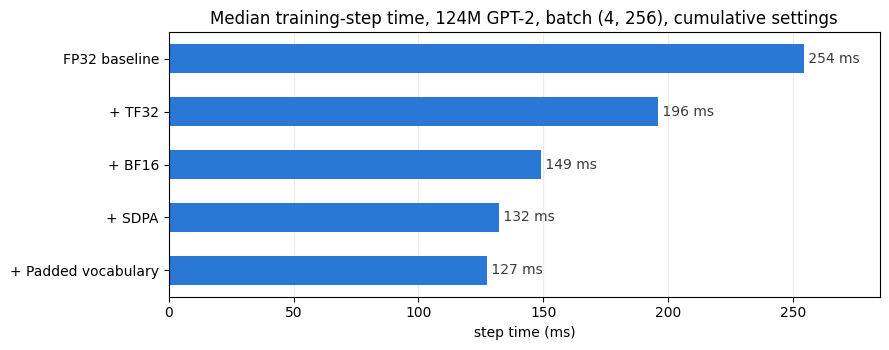

In [16]:
tokens_per_step = bench_B * bench_T
names = [cfg.name for cfg in bench_configs]
median_ms = {n_: statistics.median(run['step_ms'] for run in bench_runs[n_]) for n_ in names}
baseline_ms = median_ms[names[0]]

def table_row(n_, previous):
    runs = [run['step_ms'] for run in bench_runs[n_]]
    peak = max(run['peak_mib'] for run in bench_runs[n_])
    step_gain = '—' if previous is None else f'{median_ms[previous] / median_ms[n_]:.2f}x'
    return (f'| {n_} | {median_ms[n_]:.1f} | {min(runs):.1f} – {max(runs):.1f} | {tokens_per_step / (median_ms[n_] / 1000):,.0f} '
            f'| {baseline_ms / median_ms[n_]:.2f}x | {step_gain} | {peak:,.0f} |')

rows = ['| Configuration | Step time (ms) | Range over rounds (ms) | Tokens/s | Speedup | Gain over previous row | Peak VRAM (MiB) |',
        '|---|---:|---:|---:|---:|---:|---:|']
for i, n_ in enumerate(names):
    if n_ == '+ Padded vocabulary' and not compile_supported:
        rows.append(f'| + torch.compile | {compile_skip_reason} | | | | | |')
    rows.append(table_row(n_, names[i - 1] if i else None))
display(Markdown('\n'.join(rows)))
print(f"model: {bench_runs[names[0]][0]['n_params']:,} parameters (padded: {bench_runs[names[-1]][0]['n_params']:,}) | batch ({bench_B}, {bench_T})")

# gain of each added step, computed inside each round so that drift between rounds cancels
print('\ngain of each step inside each round:')
step_gains = {}
for prev, cur in zip(names, names[1:]):
    ratios = [p['step_ms'] / c['step_ms'] for p, c in zip(bench_runs[prev], bench_runs[cur])]
    step_gains[cur] = statistics.median(ratios)
    print(f'{cur:22s} median {step_gains[cur]:.3f}x | rounds: ' + ', '.join(f'{v:.3f}x' for v in ratios))
best_step = max(step_gains, key=step_gains.get)
fastest = min(names, key=median_ms.get)
print(f'\nlargest gain from a single step: {best_step} ({step_gains[best_step]:.2f}x)')
print(f'fastest configuration: {fastest} ({median_ms[fastest]:.1f} ms, {tokens_per_step / (median_ms[fastest] / 1000):,.0f} tokens/s, {baseline_ms / median_ms[fastest]:.2f}x)')
assert all(math.isfinite(run['loss']) for runs in bench_runs.values() for run in runs)
assert all(len(runs) == rounds for runs in bench_runs.values())

fig, ax = plt.subplots(figsize=(9, 3.6))
labels = names[::-1]
values = [median_ms[n_] for n_ in labels]
ax.barh(labels, values, color='#2a78d6', height=0.55)
for i, v in enumerate(values):
    ax.text(v, i, f' {v:.0f} ms', va='center', color='#3a3a36')
ax.set_title(f'Median training-step time, 124M GPT-2, batch ({bench_B}, {bench_T}), cumulative settings')
ax.set_xlabel('step time (ms)')
ax.set_xlim(0, max(values) * 1.12)
ax.grid(axis='x', alpha=0.25)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

### Reading the Benchmark

**Which step gained the most on my hardware?** **TF32 and BF16 are effectively tied.** In this final run, BF16 is nominally first (a median within-round gain of 1.31x against 1.30x for TF32, with rounds 1.30–1.33x and 1.28–1.31x), and the code above prints BF16 as the largest for that reason. In my previous full run of the same notebook, the order was reversed (TF32 1.31x, BF16 1.29x). A difference of 0.01x that changes sign between runs is not a ranking, so I do not claim a single winner. Together they make the step 1.71x faster. These gains are also order-dependent: BF16 is measured with TF32 already on, and they may differ on other GPUs.

**The complete result.** The fastest configuration is the last one, TF32 + BF16 + SDPA + padded vocabulary: **127.4 ms against 254.3 ms, 2.00x, 8,037 against 4,026 tokens/s**, and 399 MiB less peak memory.

**Step by step.**

- **TF32 (1.30x, same memory).** Peak VRAM is identical at 5,166 MiB, as expected: tensors are still 32-bit. The loss at the last of the 25 steps is 6.225 with and without TF32, so the lower precision made no visible difference over this short horizon.
- **BF16 (1.31x, 109 MiB less).** The logits are `bfloat16` while parameters and gradients stay `float32`, as the dtype check confirms. All losses and gradients were finite. The memory saving is small compared with the "half the memory" of a pure 16-bit model. Parameters, gradients, and two AdamW states alone take four float32 copies of 124M numbers, about 1.9 GiB, and they do not shrink. The last loss moved from 6.225 to 6.240, a small numerical difference.
- **SDPA (1.14x, a further 290 MiB less).** The outputs agree with my explicit formula to 1.8e-07 on the small test model. **This row is not Flash Attention.** The profiler shows that `_efficient_attention_forward` runs, and forcing Flash fails because *"Torch was not compiled with flash attention"*, even though `flash_sdp_enabled()` returns `True`. This Windows PyTorch build has no Flash kernel. The gain here comes from PyTorch's memory-efficient kernel, so it says nothing about what Flash would achieve on this GPU.
- **`torch.compile` (skipped).** The real attempt fails with `TritonMissing`, and I did not change the environment. This is the most important missing measurement, since it is a large gain in the lecture.
- **Padded vocabulary (1.04x, same peak after rounding).** The gain was consistent across the three rounds (1.03–1.05x) in this run and also positive in the previous one (1.02x), but it is small enough that I would not treat its size as precise. The model has 36,096 more parameters, and the 47 extra classes do participate in the softmax: their total probability starts at 0.00080 and falls to 0.00005 after 50 steps, as they are never targets. No token ID reaches them.

**Fair-comparison notes.** All rows use the same model size apart from the padding, the same batches, and the same seed. Round spreads are small (about 2% or less in each row), so the gains above 1.1x are much larger than the measurement noise. Timings cover 20 steps at a `(4, 256)` batch, which uses up to 5.0 GiB of the 6 GB. A different batch shape could change the relative gains.

# 3. GPT-3'ün eğitim ayarlarını kur. AdamW'yi videodaki beta'larla kur, gradient clipping ekle ve her adımda gradient norm'u yazdır. Warmup'lı cosine learning rate schedule yaz ve eğrisini çiz. Weight decay'i yalnız 2 boyutlu parametrelere uygula, kaç parametreye uygulandığını yaz. Sonra gradient accumulation ekle: küçük batch'lerle büyük bir batch'in gradient'ini topla. Loss'u neden accumulation adım sayısına böldüğümüzü kendi cümlelerinle yaz. (2:14:55 - 2:46:52)

## 3. GPT-3's Training Settings

### AdamW and Weight-Decay Groups

**AdamW** turns gradients into updates. It keeps a running mean of each gradient (the momentum, controlled by \(\beta_1\)) and of each squared gradient (controlled by \(\beta_2\)), so every parameter gets a step scaled by its own gradient history. Weight decay is applied directly to the weights, separately from this scaling. I use the lecture's GPT-3 values: \(\beta_1=0.9,\ \beta_2=0.95,\ \epsilon=10^{-8}\). The peak learning rate is \(3\times10^{-4}\), as in the lecture, and the weight decay is \(0.1\).

**Weight decay** pulls weights toward zero at each step, so a weight only stays large if the gradients keep supporting it. It makes sense for the matrices that do the mixing: embeddings and linear weights. Biases and LayerNorm parameters are 1D. They shift and rescale values, so pulling them to zero has no regularizing purpose and only disturbs the normalization. The rule is therefore: **`dim() >= 2` is decayed, everything else is not.**

**The tied matrix** must be counted once. `named_parameters()` skips duplicates, so `lm_head.weight` does not appear as a second entry, and it is decayed once under the name `transformer.wte.weight`.

In [17]:
def configure_optimizers(model, learning_rate, weight_decay=0.1, betas=(0.9, 0.95), eps=1e-8, fused=False):
    param_dict = {name: p for name, p in model.named_parameters() if p.requires_grad} # one entry per unique parameter
    decay_params = [p for p in param_dict.values() if p.dim() >= 2]
    nodecay_params = [p for p in param_dict.values() if p.dim() < 2]
    optim_groups = [
        {'params': decay_params, 'weight_decay': weight_decay},
        {'params': nodecay_params, 'weight_decay': 0.0},
    ]
    return torch.optim.AdamW(optim_groups, lr=learning_rate, betas=betas, eps=eps, fused=fused)

# built on the CPU: the counts do not need a GPU
counting_model = GPT(GPTConfig())
init_gpt2_weights(counting_model)
counting_optimizer = configure_optimizers(counting_model, learning_rate=3e-4)
decay_group, nodecay_group = counting_optimizer.param_groups

n_decay_tensors, n_nodecay_tensors = len(decay_group['params']), len(nodecay_group['params'])
n_decay_scalars = sum(p.numel() for p in decay_group['params'])
n_nodecay_scalars = sum(p.numel() for p in nodecay_group['params'])
print(f'decayed:     {n_decay_tensors:3d} tensors, {n_decay_scalars:>12,} parameters (weight_decay = {decay_group["weight_decay"]})')
print(f'not decayed: {n_nodecay_tensors:3d} tensors, {n_nodecay_scalars:>12,} parameters (weight_decay = {nodecay_group["weight_decay"]})')
print(f'share of the parameters that is decayed: {n_decay_scalars / (n_decay_scalars + n_nodecay_scalars):.3%}')
print('betas:', decay_group['betas'], '| eps:', decay_group['eps'], '| lr:', decay_group['lr'])

decay_ids = {id(p) for p in decay_group['params']}
nodecay_ids = {id(p) for p in nodecay_group['params']}
all_ids = {id(p) for p in counting_model.parameters()}
assert decay_ids.isdisjoint(nodecay_ids) # mutually exclusive
assert decay_ids | nodecay_ids == all_ids # every trainable parameter is covered
assert n_decay_tensors + n_nodecay_tensors == len(all_ids) == 148 # 149 state-dict names, one shared
assert n_decay_scalars + n_nodecay_scalars == 124_439_808
assert id(counting_model.transformer.wte.weight) in decay_ids
assert all(p.dim() == 2 for p in decay_group['params']) # in GPT-2, "at least 2D" is exactly 2D
for module in counting_model.modules():
    if isinstance(module, nn.LayerNorm):
        assert id(module.weight) in nodecay_ids and id(module.bias) in nodecay_ids
    elif isinstance(module, nn.Linear) and module.bias is not None:
        assert id(module.bias) in nodecay_ids and id(module.weight) in decay_ids
assert decay_group['betas'] == (0.9, 0.95) and decay_group['eps'] == 1e-8
del counting_optimizer
print('Parameter-group checks passed.')

decayed:      50 tensors,  124,318,464 parameters (weight_decay = 0.1)
not decayed:  98 tensors,      121,344 parameters (weight_decay = 0.0)
share of the parameters that is decayed: 99.902%
betas: (0.9, 0.95) | eps: 1e-08 | lr: 0.0003
Parameter-group checks passed.


### Gradient Clipping

Occasionally a batch produces an unusually large gradient, and one large update can undo many small ones. Clipping treats all gradients as one long vector \(g\) and rescales it if it is too long:

\[
g \leftarrow g\cdot\min\!\left(1,\ \frac{\texttt{max\_norm}}{\lVert g\rVert_2+10^{-6}}\right)
\]

The direction stays the same; only the length changes. `clip_grad_norm_` **returns the norm measured before clipping**, which makes it a useful number to log: it shows how large the gradient really was, and a sudden jump points to instability. If the training-loop log shows values above 1.0 at every step, then clipping is active at every step.

The check below builds a large gradient on purpose. A shared parameter appears only once in `parameters()`, so the tied gradient is also counted once.

In [18]:
max_norm = 1.0
torch.manual_seed(seed)
clip_model = GPT(GPTConfig(block_size=32, vocab_size=100, n_layer=2, n_head=4, n_embd=32))
init_gpt2_weights(clip_model)
idx = torch.randint(100, (4, 16))
_, loss = clip_model(idx, idx)
(100 * loss).backward() # a deliberately large gradient

def total_grad_norm(model):
    return torch.cat([p.grad.view(-1) for p in model.parameters()]).norm().item()

grad_before = torch.cat([p.grad.view(-1) for p in clip_model.parameters()]).clone()
norm_before = total_grad_norm(clip_model)
returned = torch.nn.utils.clip_grad_norm_(clip_model.parameters(), max_norm=max_norm)
norm_after = total_grad_norm(clip_model)
grad_after = torch.cat([p.grad.view(-1) for p in clip_model.parameters()])
print(f'norm before clipping {norm_before:.4f} | returned by clip_grad_norm_ {returned.item():.4f} | norm after clipping {norm_after:.6f}')
assert torch.isfinite(returned)
assert abs(returned.item() - norm_before) < 1e-3 * norm_before # the returned value is the norm before clipping
assert norm_after <= max_norm * (1 + 1e-5)
assert norm_before > max_norm
assert F.cosine_similarity(grad_before, grad_after, dim=0) > 0.999999 # direction preserved

# a gradient already below the limit must not change
small_norm_before = norm_after
torch.nn.utils.clip_grad_norm_(clip_model.parameters(), max_norm=10.0)
assert abs(total_grad_norm(clip_model) - small_norm_before) < 1e-6
del clip_model, idx, loss, grad_before, grad_after
print('Gradient-clipping checks passed.')

norm before clipping 168.4698 | returned by clip_grad_norm_ 168.4699 | norm after clipping 1.000000
Gradient-clipping checks passed.


### Warmup and Cosine Learning Rate

\[
\eta(t)=\begin{cases}
\eta_{max}\,\dfrac{t+1}{t_{warmup}} & t<t_{warmup}\\[2mm]
\eta_{min}+\dfrac12\left(1+\cos\!\left(\pi\,\dfrac{t-t_{warmup}}{t_{max}-t_{warmup}}\right)\right)(\eta_{max}-\eta_{min}) & t_{warmup}\le t\le t_{max}\\[2mm]
\eta_{min} & t>t_{max}
\end{cases}
\]

My values: `warmup_steps = 10`, `max_steps = 100`, `max_lr = 3e-4`, `min_lr = 3e-5` (10% of the peak, as in the lecture). These are for this short run; GPT-3-scale training uses far longer horizons.

**Why warmup.** At the start the weights are random, the gradients are large, and the optimizer's running averages have seen almost nothing, so its scaled steps are unreliable. A full-size step now could send the weights somewhere hard to recover from; my Week 10 run, which had no warmup, shows an early loss spike, although I did not isolate its cause there. Warmup keeps the first steps small until the statistics settle. The cosine part then lowers the step size gradually, because large steps that help early only bounce around the minimum later.

`+1` in the warmup makes the first learning rate nonzero, so step 0 is not wasted.

lr at steps 0, 9, 55, 100, 120: ['3.00e-05', '3.00e-04', '1.65e-04', '3.00e-05', '3.00e-05']
Learning-rate schedule checks passed.


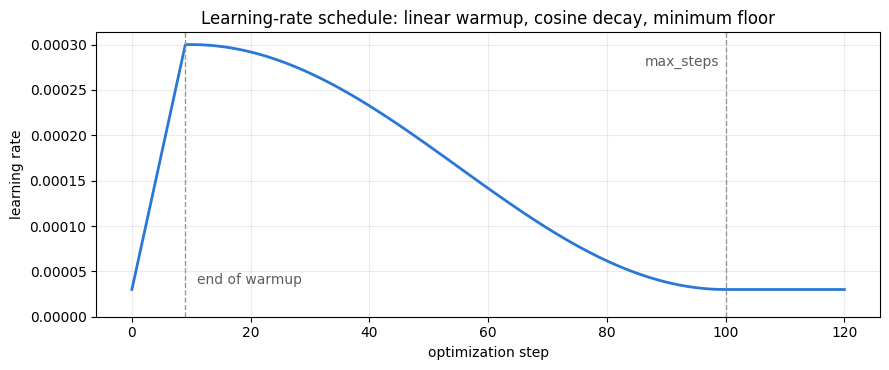

In [19]:
warmup_steps = 10
max_steps = 100
max_lr = 3e-4
min_lr = 0.1 * max_lr

def get_lr(step, warmup_steps=warmup_steps, max_steps=max_steps, max_lr=max_lr, min_lr=min_lr):
    # 1) linear warmup
    if step < warmup_steps:
        return max_lr * (step + 1) / warmup_steps
    # 2) after the horizon, stay at the minimum
    if step > max_steps:
        return min_lr
    # 3) in between, cosine decay down to the minimum
    decay_ratio = (step - warmup_steps) / (max_steps - warmup_steps)
    coeff = 0.5 * (1.0 + math.cos(math.pi * decay_ratio)) # goes from 1 to 0
    return min_lr + coeff * (max_lr - min_lr)

curve_steps = list(range(max_steps + 21)) # including 20 steps past the horizon
lrs = [get_lr(s) for s in curve_steps]

assert get_lr(0) == max_lr / warmup_steps > 0
assert all(lrs[s] < lrs[s + 1] for s in range(warmup_steps - 1)) # warmup rises strictly
assert math.isclose(lrs[warmup_steps - 1], max_lr) and math.isclose(lrs[warmup_steps], max_lr) # peak reached
assert math.isclose(max(lrs), max_lr)
assert all(lrs[s] >= lrs[s + 1] for s in range(warmup_steps, max_steps)) # cosine only falls
assert math.isclose(get_lr(max_steps), min_lr) # final value
assert all(get_lr(s) == min_lr for s in [max_steps + 1, max_steps + 20, 10 * max_steps]) # beyond the horizon
assert min(lrs) >= min_lr > 0 # never below the floor, never negative
mid = warmup_steps + (max_steps - warmup_steps) // 2
assert math.isclose(get_lr(mid), (max_lr + min_lr) / 2) # the cosine midpoint
print(f'lr at steps 0, {warmup_steps - 1}, {mid}, {max_steps}, {max_steps + 20}:', [f'{get_lr(s):.2e}' for s in [0, warmup_steps - 1, mid, max_steps, max_steps + 20]])
print('Learning-rate schedule checks passed.')

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(curve_steps, lrs, color='#2a78d6', linewidth=2)
ax.axvline(warmup_steps - 1, color='#9a9a94', linewidth=1, linestyle='--')
ax.axvline(max_steps, color='#9a9a94', linewidth=1, linestyle='--')
ax.text(warmup_steps + 1, min_lr * 1.2, 'end of warmup', color='#5f5f5a')
ax.text(max_steps - 1, max_lr * 0.92, 'max_steps', ha='right', color='#5f5f5a')
ax.set_title('Learning-rate schedule: linear warmup, cosine decay, minimum floor')
ax.set_xlabel('optimization step')
ax.set_ylabel('learning rate')
ax.set_ylim(bottom=0)
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

### Gradient Accumulation

I want the gradient of a batch that does not fit in my 6 GB, so I compute it piece by piece:

\[
\texttt{effective\_batch\_size} = \texttt{micro\_batch\_size}\times\texttt{accumulation\_steps}
\]

For example, 4 microbatches of 2 give the gradient of a batch of 8. `loss.backward()` **adds** to `p.grad` as long as gradients are not zeroed, so the optimizer steps once, after the last microbatch.

**Why I divide the loss by the number of accumulation steps.** `F.cross_entropy` returns the *mean* over the targets. The loss I want is the mean over the large batch. With \(k\) equal microbatches, that mean is the mean of their means:

\[
L=\frac{L_1+L_2+\dots+L_k}{k}
\qquad\Rightarrow\qquad
\nabla L=\sum_{i=1}^{k}\nabla\!\left(\frac{L_i}{k}\right)
\]

If I just call `backward()` on each \(L_i\), then the additions give \(\sum_i\nabla L_i=k\nabla L\): a gradient about \(k\) times too large, as if I had summed the losses rather than averaged them. Dividing each \(L_i\) by \(k\) before `backward()` makes the sum of what is accumulated equal to the gradient of the average. Without it, the size of the gradient would depend on how many pieces I happened to split the batch into. Clipping would then cut it by much more, and the update would no longer match the large batch.

This requires microbatches of **equal size** with the same number of targets; otherwise the mean of means is not the overall mean.

**The numerical test** compares the gradient of one large batch with the accumulated gradient on the same samples, with no optimizer step in between. The model has no dropout, so both passes are deterministic functions of the samples. I report \(\lVert g_{large}-g_{acc}\rVert_2/\lVert g_{large}\rVert_2\), and I set the tolerances in advance from the precision of each mode:

| Mode | Purpose | Tolerance |
|---|---|---:|
| Small model, float64, CPU | proves the math with rounding almost removed | 1e-10 |
| 124M, float32, explicit attention, GPU | the full model at full float32 precision | 1e-3 |
| 124M, BF16 + TF32 + SDPA, GPU | the settings of the training run; 7-bit mantissas | 5e-2 |

As a negative control, the same accumulation **without** the division must give a gradient about \(k\) times too long.

In [20]:
def large_batch_grads(model, x, y, autocast=False):
    model.zero_grad(set_to_none=True)
    with torch.autocast(device_type='cuda', dtype=torch.bfloat16, enabled=autocast):
        _, loss = model(x, y)
    loss.backward()
    return torch.cat([p.grad.view(-1) for p in model.parameters()]).clone()

def accumulated_grads(model, x, y, accumulation_steps, autocast=False, divide=True):
    model.zero_grad(set_to_none=True)
    for x_micro, y_micro in zip(x.chunk(accumulation_steps), y.chunk(accumulation_steps)):
        with torch.autocast(device_type='cuda', dtype=torch.bfloat16, enabled=autocast):
            _, loss = model(x_micro, y_micro)
        if divide:
            loss = loss / accumulation_steps
        loss.backward() # adds to p.grad; no optimizer step
    return torch.cat([p.grad.view(-1) for p in model.parameters()]).clone()

def compare_grads(label, model, x, y, k, tolerance, autocast=False):
    g_large = large_batch_grads(model, x, y, autocast)
    g_acc = accumulated_grads(model, x, y, k, autocast)
    relative = ((g_large - g_acc).norm() / g_large.norm()).item()
    max_abs = (g_large - g_acc).abs().max().item()
    print(f'{label:34s} | batch {x.size(0)} = {x.size(0) // k} x {k} | relative difference {relative:.3e} | max abs {max_abs:.3e} | tolerance {tolerance:.0e}')
    assert torch.isfinite(g_large).all() and torch.isfinite(g_acc).all()
    assert relative < tolerance
    return g_large, g_acc, relative

micro_batch_size, grad_accum_steps = 2, 4
accum_B, accum_T = micro_batch_size * grad_accum_steps, 128
x_accum, y_accum = DataLoaderLite(tokens, accum_B, accum_T).next_batch()

# 1) small model, float64, CPU
torch.manual_seed(seed)
toy_model = GPT(GPTConfig(block_size=128, vocab_size=50257, n_layer=2, n_head=4, n_embd=32))
init_gpt2_weights(toy_model)
toy_model.double()
before = {name: p.clone() for name, p in toy_model.named_parameters()}
compare_grads('small model, float64, CPU', toy_model, x_accum, y_accum, grad_accum_steps, 1e-10)
assert all(torch.equal(before[name], p) for name, p in toy_model.named_parameters()) # no update happened
del toy_model, before

# 2) 124M, float32, explicit attention
set_tf32(False)
model = build_model(GPTConfig())
x_gpu, y_gpu = x_accum.to(device), y_accum.to(device)
g_large, g_acc, _ = compare_grads('124M, float32, GPU', model, x_gpu, y_gpu, grad_accum_steps, 1e-3)

# negative control: the same accumulation without dividing the loss
g_undivided = accumulated_grads(model, x_gpu, y_gpu, grad_accum_steps, divide=False)
norm_ratio = (g_undivided.norm() / g_large.norm()).item()
print(f'without dividing by k: gradient norm is {norm_ratio:.4f} x the large-batch norm (k = {grad_accum_steps})')
assert abs(norm_ratio - grad_accum_steps) < 1e-2
del model, g_large, g_acc, g_undivided
release_memory()

# 3) the settings of the training run
set_tf32(True)
model = build_model(GPTConfig(vocab_size=50304, sdpa=True))
g_large, g_acc, _ = compare_grads('124M, BF16 + TF32 + SDPA, GPU', model, x_gpu, y_gpu, grad_accum_steps, 5e-2, autocast=True)
set_tf32(False)
del model, g_large, g_acc, x_gpu, y_gpu
release_memory()
print('Gradient-accumulation equivalence checks passed.')

small model, float64, CPU          | batch 8 = 2 x 4 | relative difference 2.515e-16 | max abs 8.327e-17 | tolerance 1e-10


124M, float32, GPU                 | batch 8 = 2 x 4 | relative difference 6.656e-07 | max abs 4.470e-07 | tolerance 1e-03


without dividing by k: gradient norm is 4.0000 x the large-batch norm (k = 4)


124M, BF16 + TF32 + SDPA, GPU      | batch 8 = 2 x 4 | relative difference 4.880e-03 | max abs 1.465e-03 | tolerance 5e-02
Gradient-accumulation equivalence checks passed.


### Everything Together

The final run combines the sequential loader, the AdamW groups, the schedule, BF16 autocast, TF32, SDPA, the padded vocabulary, clipping, and accumulation:

- **Batch:** microbatch `(4, 128)`, 4 accumulation steps, effective batch 16, so 2,048 tokens per optimization step.
- **Learning rate:** the schedule above, `max_steps = 100`. The rate is set just before each optimizer step.
- **Optimizer:** `configure_optimizers` with `fused=True`, as in the lecture. Unlike the benchmark, this run uses the fused AdamW, so its timings are not directly comparable with the table above. `torch.compile` is not used, as Task 2 found it unavailable here.

The log is printed at every optimization step, as the assignment asks. The reported loss is the mean over the microbatches. Step time covers all four microbatches and the update, and it includes moving the batches to the GPU.

In [21]:
set_tf32(True)
torch.cuda.reset_peak_memory_stats()
model = build_model(GPTConfig(vocab_size=50304, sdpa=True))
optimizer = configure_optimizers(model, learning_rate=max_lr, fused=True)
micro_B, micro_T, accum_steps = 4, 128, 4
tokens_per_opt_step = micro_B * micro_T * accum_steps
loader = DataLoaderLite(tokens, micro_B, micro_T)
history = {'loss': [], 'lr': [], 'grad_norm': [], 'step_ms': []}

print('step | loss | lr | grad_norm | step_time_ms | tokens_per_sec')
for step in range(max_steps):
    torch.cuda.synchronize()
    t0 = time.perf_counter()
    optimizer.zero_grad(set_to_none=True)
    loss_accum = 0.0
    for micro_step in range(accum_steps):
        x, y = loader.next_batch()
        x, y = x.to(device), y.to(device)
        with torch.autocast(device_type='cuda', dtype=torch.bfloat16):
            logits, loss = model(x, y)
        loss = loss / accum_steps # the mean over the k microbatches, not their sum
        loss_accum += loss.detach()
        loss.backward()
    grad_norm = torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=max_norm) # the norm before clipping
    assert torch.isfinite(grad_norm), f'non-finite gradient norm at step {step}'
    lr = get_lr(step)
    for param_group in optimizer.param_groups:
        param_group['lr'] = lr
    optimizer.step()
    torch.cuda.synchronize()
    dt = time.perf_counter() - t0
    loss_value = float(loss_accum)
    assert math.isfinite(loss_value), f'non-finite loss at step {step}'
    history['loss'].append(loss_value)
    history['lr'].append(lr)
    history['grad_norm'].append(grad_norm.item())
    history['step_ms'].append(dt * 1000)
    print(f'{step:4d} | {loss_value:.4f} | {lr:.2e} | {grad_norm.item():7.4f} | {dt * 1000:7.1f} | {tokens_per_opt_step / dt:8,.0f}')
peak_mib = torch.cuda.max_memory_allocated() / 2**20
set_tf32(False)

step | loss | lr | grad_norm | step_time_ms | tokens_per_sec


   0 | 10.9153 | 3.00e-05 | 28.5958 |   464.0 |    4,413


   1 | 9.7041 | 6.00e-05 | 13.1453 |   262.2 |    7,810


   2 | 9.3850 | 9.00e-05 | 13.5712 |   259.5 |    7,892


   3 | 9.5454 | 1.20e-04 |  8.8946 |   258.0 |    7,938


   4 | 9.1795 | 1.50e-04 |  4.6301 |   258.3 |    7,929


... (91 outputs left out)

  96 | 5.9692 | 3.13e-05 |  1.1398 |   224.3 |    9,131


  97 | 5.9561 | 3.07e-05 |  1.2053 |   218.0 |    9,393


  98 | 5.8481 | 3.03e-05 |  1.0968 |   220.8 |    9,274


  99 | 5.8462 | 3.01e-05 |  1.0674 |   222.0 |    9,225


optimization steps: 100 | tokens read: 204,800 of 338,025 in the corpus | epochs finished: 0
loss: first 10.9153 | last 5.8462 | mean of the last 10 5.9246
median step: 220.5 ms (9,288 tokens/s) | peak VRAM: 3,634 MiB
grad norm: first 28.596 | max 45.208 | last 1.067 | steps above the clip limit: 100 of 100
Integrated-training checks passed.


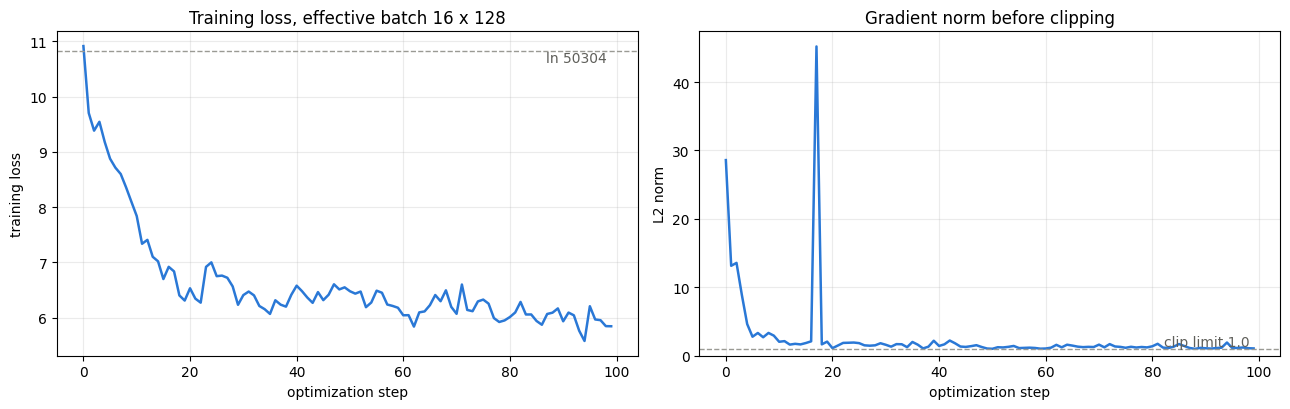

saved: week-11/training_loss.png


In [22]:
n_steps = len(history['loss'])
median_step_ms = statistics.median(history['step_ms'][1:])
print(f"optimization steps: {n_steps} | tokens read: {n_steps * tokens_per_opt_step:,} of {len(tokens):,} in the corpus | epochs finished: {loader.epoch}")
print(f"loss: first {history['loss'][0]:.4f} | last {history['loss'][-1]:.4f} | mean of the last 10 {sum(history['loss'][-10:]) / 10:.4f}")
print(f"median step: {median_step_ms:.1f} ms ({tokens_per_opt_step / (median_step_ms / 1000):,.0f} tokens/s) | peak VRAM: {peak_mib:,.0f} MiB")
print(f"grad norm: first {history['grad_norm'][0]:.3f} | max {max(history['grad_norm']):.3f} | last {history['grad_norm'][-1]:.3f} | steps above the clip limit: {sum(g > max_norm for g in history['grad_norm'])} of {n_steps}")

assert n_steps == max_steps
assert all(math.isfinite(v) for v in history['loss'] + history['grad_norm'])
assert history['lr'] == [get_lr(s) for s in range(max_steps)]
assert optimizer.param_groups[0]['betas'] == (0.9, 0.95)
assert sum(history['loss'][-10:]) < sum(history['loss'][:10])
print('Integrated-training checks passed.')

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].plot(range(n_steps), history['loss'], color='#2a78d6', linewidth=1.8)
axes[0].axhline(math.log(50304), color='#9a9a94', linewidth=1, linestyle='--')
axes[0].text(n_steps - 1, math.log(50304), 'ln 50304 ', ha='right', va='top', color='#5f5f5a')
axes[0].set_title('Training loss, effective batch 16 x 128')
axes[0].set_xlabel('optimization step')
axes[0].set_ylabel('training loss')
axes[0].grid(alpha=0.25)
axes[1].plot(range(n_steps), history['grad_norm'], color='#2a78d6', linewidth=1.8)
axes[1].axhline(max_norm, color='#9a9a94', linewidth=1, linestyle='--')
axes[1].text(n_steps - 1, max_norm, 'clip limit 1.0 ', ha='right', va='bottom', color='#5f5f5a')
axes[1].set_title('Gradient norm before clipping')
axes[1].set_xlabel('optimization step')
axes[1].set_ylabel('L2 norm')
axes[1].set_ylim(bottom=0)
axes[1].grid(alpha=0.25)
plt.tight_layout()
loss_plot_path = output_dir / 'training_loss.png'
fig.savefig(loss_plot_path, dpi=120)
plt.show()
print('saved:', loss_plot_path.relative_to(repo_dir).as_posix())
assert loss_plot_path.exists()
del model, optimizer, logits, loss, x, y
release_memory()

### Reading the Task 3 Results

**Parameter groups.** Weight decay applies to **50 tensors with 124,318,464 parameters** (99.9%): the shared embedding matrix, `wpe`, and the 48 linear weights. It does not apply to **98 tensors with 121,344 parameters**: 48 linear biases and 50 LayerNorm tensors. These add up to 148 tensors, one fewer than the 149 state-dict names because of tying, and to exactly 124,439,808 parameters. The groups are disjoint and complete.

**Accumulation.** All three comparisons pass the tolerances I fixed before running them. The relative differences are 2.5e-16 in float64, which is rounding alone, 6.7e-07 in float32, and 4.9e-03 under BF16. The two BF16 gradients are close but not identical, which fits its 7-bit mantissa, although I did not isolate the source of the difference. Without the division, the gradient norm is 4.0000 times the large-batch norm for \(k=4\), which is exactly the error the division removes.

**Training run.** In 100 optimization steps of 2,048 tokens each, the loss goes from 10.92 to a final 5.85 (mean of the last 10 steps: 5.92), with all values finite. The run reads 204,800 tokens, about 61% of the corpus, so it does not finish an epoch. The median step takes 220.5 ms, or 9,288 tokens/s, with a peak of 3,634 MiB.

**Gradient norms.** The norm starts at 28.6 and falls toward about 1 over the run. The **most instructive point is step 17**, where it jumps to **45.2** for one step. Clipping rescaled that gradient to length 1 before AdamW used it, and the loss at the next step kept falling (6.84 to 6.40). This is the kind of event clipping is for, but I did not repeat the run without clipping, so I cannot say what would have happened otherwise.

The norm was above 1.0 at **all 100 steps**, though only slightly at the end (the last is 1.07). So in this run clipping acted at every step, not only on rare spikes.

**A comparison I do not make.** This run's final loss is not directly comparable with Task 1's. They differ in batch, learning-rate schedule, number of tokens, and the part of the text they end on.

## Final Notes

- **Data loader.** `DataLoaderLite` walks through all 338,025 GPT-2 tokens of Tiny Shakespeare. Tests confirm the one-token shift, different and contiguous batches, in-order coverage of an epoch, and safe wrapping. One epoch of `(8, 128)` batches takes 330 steps and brings the mean loss from 7.86 (first 20 steps) to 5.45 (last 20 steps).
- **Weight tying.** `wte.weight` and `lm_head.weight` are one parameter, which saves **38,597,376** numbers. The model has 124,439,808 unique parameters, while its state dict sums to 163,037,184.
- **Initialization.** Measured standard deviations are 0.0200 for ordinary weights and 0.00408 for residual projections. Scaling lowers the residual stream at the last block from 1.567 to 0.299.
- **Speed.** Measured on the RTX 3060 Laptop GPU, 124M, batch `(4, 256)`, cumulative:

| Configuration | Step time (ms) | Tokens/s | Speedup | Peak VRAM (MiB) |
|---|---:|---:|---:|---:|
| FP32 baseline | 254.3 | 4,026 | 1.00x | 5,166 |
| + TF32 | 196.1 | 5,222 | 1.30x | 5,166 |
| + BF16 | 149.0 | 6,870 | 1.71x | 5,057 |
| + SDPA (efficient kernel, not Flash) | 132.3 | 7,741 | 1.92x | 4,767 |
| + torch.compile | Skipped — torch.compile requires a compatible compilation backend unavailable in the current Windows environment. | | | |
| + Padded vocabulary | 127.4 | 8,037 | 2.00x | 4,767 |

- **Largest gain.** TF32 and BF16 are effectively tied at about 1.3x each; their order changed between two full runs.
- **Training settings.** AdamW uses betas 0.9 and 0.95 with \(\epsilon=10^{-8}\). Decay applies to 50 tensors (124,318,464 parameters) and not to 98 tensors (121,344 parameters). The schedule, clipping, and accumulation all pass their tests. Accumulated and large-batch gradients agree to a relative 6.7e-07 in float32, and omitting the division makes the gradient 4.0000 times too long.
- **Integrated run.** 100 optimization steps with an effective batch of 16 × 128 take the loss from 10.92 to 5.85, with one gradient spike of 45.2 clipped at step 17.

## Limitations

- **Batch size:** the benchmark uses `(4, 256)` because the lecture's `(16, 1024)` does not fit in 6 GB. The relative gains may differ at other sizes.
- **Benchmark scope:** 3 rounds of 20 measured steps on one laptop GPU, whose speed also depends on temperature and power state. Each gain depends on the order of the cumulative steps. I did not measure each setting alone. Peak VRAM is PyTorch's allocated memory, not the driver's total.
- **Not measured:** real Flash Attention (this Windows PyTorch build was not compiled with it) and `torch.compile` (Triton is not installed). My table does not show what this GPU could reach with them. FP16 was not tried, since BF16 is supported.
- **Numerical cost of the speed-ups:** I checked finiteness and a short loss comparison only. I did not study how TF32 and BF16 affect final model quality over a long run.
- **Training:** training loss only, on one small English corpus. No train/validation split, no held-out loss, no generated samples, and no checkpoints. Task 1 runs one epoch and the integrated run covers about 61% of one. Only one seed was used.
- **Clipping:** the gradient norm stayed above the limit at all 100 steps. I did not test other limits or a run without clipping, so clipping's benefit is not measured and the cause of the spike at step 17 is unknown.
- **Accumulation test:** one batch of 8 sequences, split into 4 equal parts. Unequal microbatches would need weighting by their size.
- **Not attempted:** the optional DDP and tokenizer-comparison tasks are not part of this notebook. Full GPT-2 pretraining is the next step.